# A 1-D diffusion model

Here we develop a 1-d numerical model of diffiusion

Here is the diffusion equation: $$ \frac{\partial z}{\partial t} = D\frac{\partial^2 z}{\partial x^2} $$

Here $z$ is elevation, $x$ is the spaital demension, and $D$ is the transport rate coefficent (of diffusivity). 

The discretized version of this equation is:

$$ z^{t+1}_x = z^t_x + {D \Delta t \over \Delta x^2} (z^t_{x+1} - 2z^t_x + z^t_{x-1}) $$

^ This is the FTCS scheme for solving diffusion equations.

We will use two Python libraries, NumPy (for arrays) and MatPlotlib (for plotting), that arent a part of the core Pyhton library.

In [14]:
import numpy as np 
import matplotlib.pyplot as plt

Start by setting 2 fixed model paramters, the diffusivity and the size of the model domain. 

In [15]:
D = 100 #D = Diffusivity
Lx = 300 #Lx = model domain

Next set up the model grid using a NumPy array.

In [16]:
dx = 0.5 #grid spacing 
x = np.arange(start = 0, stop = Lx, step = dx) #the grid
nx = len(x) #number of grid nodes

Set the inital conditions for the model. 
The elevation $z$ is a step function with a high value on the left, a low value on the right, and a cliff at the center of the domain.

In [17]:
z = np.zeros_like(x) #elevation
z_left = 500
z_right = 0
z[x <= Lx /2] = z_left #step
z[x > Lx/2] = z_right

Plot the inital conidtions od the model.

Text(0.5, 1.0, 'Inital profile')

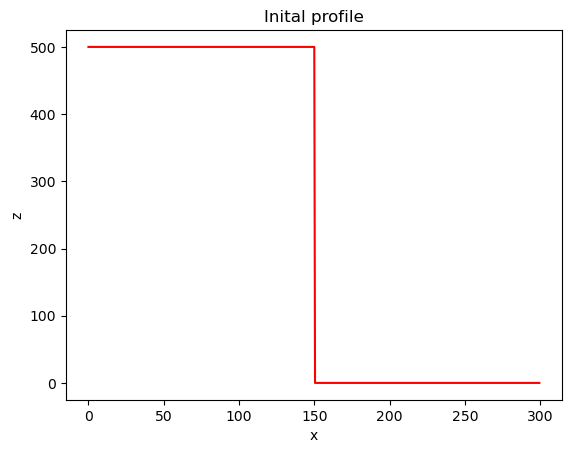

In [18]:
plt.figure()
plt.plot(x, z, "r")
plt.xlabel("x")
plt.ylabel("z")
plt.title("Inital profile")

Set the number of time steps in the model. 
Calculate a stable time step using a stablity criterion.

In [19]:
nt = 500 #number of time steps
dt = 0.5 * dx**2 / D #Time step

Loop over the time steps of the model, solving the diffusion equation using the FTCS scheme described above. 

In [20]:
for t in range(0, nt):
	z[1:-1] += D * dt / dx ** 2 * (z[:-2] - 2*z[1:-1] + z[2:])

Note that this is an array operation on the elevation $z$. 
The boundary conditions remain fixed in each time step. 

Plot the result of running the model.

Text(0.5, 1.0, 'Final profile')

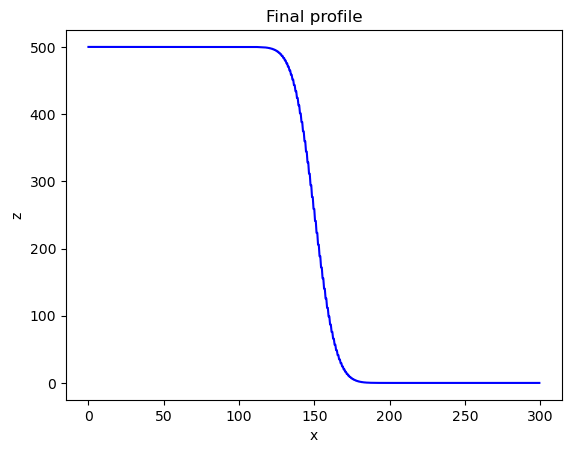

In [21]:
plt.figure()
plt.plot(x, z, "b")
plt.xlabel("x")
plt.ylabel("z")
plt.title("Final profile")